# 과제 II: 다요인 모형과 요인추출

**데이터**: `QuantDataR.xlsx` (월별 792개 종목, 2006-08 ~ 2020-09, Datastream)
**참고문헌**: Han, Lee and Kang (2020), "Market anomalies in the Korean stock market", *JDQS* 28(2) — 이하 "논문"

### 과제 내용
1. **개별자산의 수익률을 가장 잘 설명하는 모형 수립** — 기업특성 $A_{ikt}$ 를 설명변수로 사용
   - 동시점 회귀: $r_{it} = \alpha + \sum_k \beta_k A_{ikt} + \varepsilon_{it}$
   - 예측 회귀(16개월 전 설명변수): $r_{it} = \alpha + \sum_k \beta_k A_{ik,t-16} + \varepsilon_{it}$
   - 모형 성과의 변화 / 예측력 있는 변수 / 두 회귀의 비교 / 예측력의 원천 / 이상치의 영향
2. **요인의 계산** — 기업특성으로 헤지포트폴리오를 만들고, 수익률이 0과 다른지 검정하며, 누적수익률을 계산

### 분석 방법 요약
- 논문의 6개 범주(Value, Momentum, Investment, Profitability, Intangible, Trading friction)에서 이 데이터셋으로 계산 가능한 **17개 특성**을 구성했습니다.
- 회귀는 매월 횡단면 회귀를 추정한 뒤 계수의 시계열 평균을 검정하는 **Fama-MacBeth** 방식이며, t-값은 논문과 같이 **Newey-West** 표준오차를 사용합니다.
- 유의성 기준은 논문과 같이 단일검정 $|t|>1.96$ 과 다중검정 $|t|>2.78$ (Harvey et al., 2016) 두 가지를 봅니다.
- 요인은 5분위 정렬 후 **High − Low** 헤지포트폴리오로 계산하고, 논문의 핵심 논점인 **가치가중(VW) vs 동일가중(EW)** 을 비교합니다.

In [1]:
import os, tempfile, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

## 0. 설정 및 데이터 읽기

In [2]:
############################################################################################
# Settings (변경 가능한 설정값)
LAGS        = 16            # 설명변수 시차 (개월)
WINSOR      = 0.02          # 횡단면 winsorize 한도 (하위 2%, 상위 98%)  -> 수업 코드의 Upper_limit = 0.98 과 동일
MIN_STOCKS  = 100           # 횡단면 회귀/포트폴리오 구성에 필요한 최소 종목 수
NW_LAGS     = 4             # Newey-West 시차
START, END  = '2009-01', '2020-07'   # 모든 모형에 공통으로 적용하는 표본기간 (시차 28개월 확보 후 ~ 시장자료 종료월)
N_PORT      = 5             # 헤지포트폴리오 분위수 (5분위)

In [3]:
############################################################################################
# Read Data
candidates = ['../data/QuantDataR.xlsx', 'data/QuantDataR.xlsx', 'quant-finance/data/QuantDataR.xlsx',
              'QuantDataR.xlsx', '/gdrive/MyDrive/QuantFinance/QuantDataR.xlsx']
# Colab 사용 시:  from google.colab import drive; drive.mount('/gdrive')
data_path = next(p for p in candidates if os.path.exists(p))

cache = os.path.join(tempfile.gettempdir(), 'QuantDataR_cache.pkl')   # 엑셀(96MB) 재읽기 방지를 위한 임시 캐시
if os.path.exists(cache) and os.path.getmtime(cache) > os.path.getmtime(data_path):
    df = pickle.load(open(cache, 'rb'))
else:
    df = pd.read_excel(data_path, None, index_col=0)
    pickle.dump(df, open(cache, 'wb'))

print(list(df.keys()))

['D_Market', 'D_RI', 'D_TradingValue', 'D_P', 'M_Market', 'Beta', 'Volatility', 'DY', 'RI', 'TradingValue', 'Cash', 'AccReceivables', 'Inventory', 'CurrentAsset', 'R&D', 'Plants', 'Intangible', 'Total Asset', 'AccPayable', 'CurrentLiability', 'LongTermDebt', 'TotalLiability', 'CommonEquity', 'TotalShareEqu', 'Sales', 'CoGS', 'DepArm', 'OperatingIncome', 'EBIT', 'Interest', 'NetIncome', 'DividendPerShare', 'EPS', 'CommonShares', 'Investment', 'Employee', 'WorkingCap', 'MarketValue']


In [4]:
############################################################################################
# 월별 시트 정리: 날짜 인덱스 / 기업명 컬럼 / 숫자형 변환
firm_names = [str(c).replace(' - TOT RETURN IND', '') for c in df['RI'].columns]

def sheet(name):
    d = df[name].copy()
    d.index = pd.to_datetime(d.index)
    d.columns = firm_names
    return d.apply(pd.to_numeric, errors='coerce')      # '#ERROR' 등 문자열은 NaN 처리

RI  = sheet('RI')
ME  = sheet('MarketValue')            # 시가총액 (백만원)
TV  = sheet('TradingValue')           # 거래대금
RI  = RI.where(RI > 0)

# 단순수익률(%) : 포트폴리오 수익률 계산을 위해 로그수익률 대신 단순수익률 사용
R = RI.pct_change(fill_method=None) * 100

# 거래가 없는데 지수값만 반복되는 구간(거래정지/상장폐지 후 값 반복)은 수익률에서 제외
stale = (R == 0) & (TV.isna() | (TV == 0))
R = R.mask(stale)

print('기간:', R.index[1].date(), '~', R.index[-1].date(), '| 종목수:', R.shape[1])
print('월별 유효 종목 수'); print(R.notna().sum(axis=1).iloc[12::24].to_string())
print(R.stack().describe(percentiles=[.01, .5, .99]).to_string())

기간: 2006-09-29 ~ 2020-09-30 | 종목수: 792
월별 유효 종목 수
Name
2007-08-31    575
2009-08-31    609
2011-08-31    660
2013-08-30    677
2015-08-31    702
2017-08-31    742
2019-08-30    768
count   114,485.000
mean          1.165
std          14.965
min         -94.967
1%          -29.481
50%           0.000
99%          48.027
max         777.045


In [5]:
############################################################################################
# 시장수익률, 무위험수익률 (M_Market 시트)
MK = df['M_Market'].copy(); MK.index = pd.to_datetime(MK.index)
kospi = pd.to_numeric(MK.iloc[:, 0], errors='coerce')
call  = pd.to_numeric(MK.iloc[:, 5], errors='coerce')        # 콜금리 (연율 %)
RM = kospi.pct_change() * 100
RF = call.shift(1) / 12                                      # 월 무위험수익률 (%)
MKT = (RM - RF).rename('MKT')
MKT.loc[START:END].describe()

count   139.000
mean      0.432
std       4.489
min     -13.502
25%      -1.979
50%       0.638
75%       3.084
max      13.374
Name: MKT, dtype: float64

In [6]:
############################################################################################
# 회계자료의 갱신 시점 확인: 연 1회, 1월에 값이 바뀜 (회계연도 Y의 값이 Y년 1월부터 표시됨)
TA = sheet('Total Asset')
chg = (TA.diff() != 0) & TA.notna() & TA.shift().notna()
print(chg.sum(axis=1).groupby(chg.index.month).sum().rename('자산총계 값이 변한 횟수(월별)').to_string())

Name
1     8512
2        0
3        0
4      343
5        0
6        0
7       71
8        0
9        0
10      44
11       0
12      13


**16개월 시차의 의미.** 회계자료는 연 1회, 1월에 값이 바뀝니다. 즉 회계연도 $Y$ 의 재무제표 값이 $Y$년 1월부터 표시되므로, 이를 동시점으로 쓰면 아직 공시되지 않은 정보를 쓰게 됩니다(look-ahead bias).
16개월 시차를 주면 회계연도 $Y$ 의 값은 $Y+1$년 5월 ~ $Y+2$년 4월 수익률에만 사용됩니다. 12월 결산 후 사업보고서가 공시되는 3월 말 이후에만 쓰게 되므로, 논문에서 $t-1$ 회계연도 자료를 $t$년 6월 말부터 쓰는 것과 같은 취지입니다.

## 1. 기업특성 변수 구성

논문 Table 1 의 이상현상 중 데이터셋에 있는 항목으로 계산할 수 있는 것을 골랐습니다.

| 범주 | 변수 | 정의 | 논문의 대응 변수 |
|---|---|---|---|
| Value | BM, EP, SP, DM, DY | 자기자본·순이익·매출·총부채 / 시가총액, 배당수익률 | Bm, Ep, Sp, Dm, Dp |
| Profitability | GPA, ROE, OPA | (매출−매출원가)/자산, 순이익/자기자본, 영업이익/자산 | Gpa, Roe, Opa |
| Investment | AG, OA | 자산성장률, 영업발생액/전기자산 | I/A, Oa |
| Intangible | RDM | R&D/시가총액 (R&D>0 인 기업만) | Rdm |
| Momentum | MOM | 직전 1개월을 제외한 과거 11개월 누적수익률 | R¹¹1 |
| Trading friction | SIZE, BETA, VOL, TURN, DTV | log 시가총액, 베타, 변동성, 거래회전율, 거래대금 | β, Tv, Tur, Dtv |

세 가지 시점 조합을 비교합니다.
- **모형 A** (동시점): 모든 특성을 $t$ 시점 값으로 — 과제의 첫 번째 식
- **모형 B** (전체 16개월 시차): 모든 특성을 $t-16$ 시점 값으로 — 과제의 두 번째 식
- **모형 C** (실행 가능한 예측모형): 회계자료는 $t-16$, 시장자료(시가총액·모멘텀·변동성·거래)는 $t-1$ — 요인 포트폴리오 구성에 사용

In [7]:
############################################################################################
# 기업특성(Firm Characteristics) 계산 함수
#   acc_lag : 회계자료 시차,  mkt_lag : 시장자료(베타, 변동성, 모멘텀, 거래) 시차,  me_lag : 비율 분모로 쓰는 시가총액 시차
acc = {k: sheet(k) for k in ['CommonEquity', 'NetIncome', 'Sales', 'CoGS', 'TotalLiability', 'Total Asset', 'R&D',
                             'Cash', 'CurrentAsset', 'CurrentLiability', 'DepArm', 'OperatingIncome']}
mkt = {k: sheet(k) for k in ['Beta', 'Volatility', 'DY']}

CATEGORY = {'BM': 'Value', 'EP': 'Value', 'SP': 'Value', 'DM': 'Value', 'DY': 'Value',
            'GPA': 'Profitability', 'ROE': 'Profitability', 'OPA': 'Profitability',
            'AG': 'Investment', 'OA': 'Investment',
            'RDM': 'Intangible',
            'MOM': 'Momentum',
            'SIZE': 'Trading friction', 'BETA': 'Trading friction', 'VOL': 'Trading friction',
            'TURN': 'Trading friction', 'DTV': 'Trading friction'}

def build_chars(acc_lag, mkt_lag, me_lag):
    A  = {k: v.shift(acc_lag) for k, v in acc.items()}
    A1 = {k: v.shift(acc_lag + 12) for k, v in acc.items()}          # 전년도 회계자료
    me = (ME * 1000).shift(me_lag)                                    # 회계자료(천원) 단위에 맞춤
    BE = A['CommonEquity'].where(A['CommonEquity'] > 0)
    TA_, TA1 = A['Total Asset'].where(A['Total Asset'] > 0), A1['Total Asset'].where(A1['Total Asset'] > 0)
    C = {}
    # --- Value
    C['BM']  = BE / me                                                # 장부가/시가 (Bm)
    C['EP']  = A['NetIncome'] / me                                    # 이익/주가 (Ep)
    C['SP']  = A['Sales'] / me                                        # 매출/시가 (Sp)
    C['DM']  = A['TotalLiability'] / me                               # 부채/시가 (Dm)
    C['DY']  = mkt['DY'].shift(mkt_lag)                               # 배당수익률 (Dp)
    # --- Profitability
    C['GPA'] = (A['Sales'] - A['CoGS']) / TA_                         # 매출총이익/자산 (Gpa)
    C['ROE'] = A['NetIncome'] / BE                                    # Roe
    C['OPA'] = A['OperatingIncome'] / TA_                             # 영업이익/자산 (Opa)
    # --- Investment
    C['AG']  = TA_ / TA1 - 1                                          # 자산성장률 (I/A)
    d = lambda k: A[k] - A1[k]
    C['OA']  = (d('CurrentAsset') - d('Cash') - d('CurrentLiability') - A['DepArm']) / TA1    # 영업발생액 (Oa)
    # --- Intangible
    C['RDM'] = A['R&D'].where(A['R&D'] > 0) / me                      # R&D/시가 (Rdm)
    # --- Momentum : 직전 1개월을 제외한 과거 11개월 누적수익률 (R11)
    C['MOM'] = (RI.shift(1) / RI.shift(12) - 1).shift(mkt_lag) * 100
    # --- Trading friction
    C['SIZE'] = np.log(ME.shift(me_lag))                              # log 시가총액
    C['BETA'] = mkt['Beta'].shift(mkt_lag)
    C['VOL']  = mkt['Volatility'].shift(mkt_lag)
    tv = TV.where(TV > 0).shift(mkt_lag)
    C['TURN'] = np.log(tv / ME.shift(mkt_lag))                        # 거래회전율 (Tur)
    C['DTV']  = np.log(tv)                                            # 거래대금 (Dtv)
    return {k: v.replace([np.inf, -np.inf], np.nan) for k, v in C.items()}

# 모형 A: 동시점 특성 A_t            (과제의 첫 번째 회귀식)
# 모형 B: 모든 특성을 16개월 전으로    (과제의 두 번째 회귀식, A_{t-16})
# 모형 C: 회계자료 16개월 전 + 시장자료 1개월 전  (실제로 투자에 쓸 수 있는 정보만 사용하는 예측모형)
CH = {'A': build_chars(0, 0, 0), 'B': build_chars(LAGS, LAGS, LAGS), 'C': build_chars(LAGS, 1, 1)}
MODEL_NAME = {'A': 'A: 동시점 A(t)', 'B': 'B: 전체 16개월 시차 A(t-16)', 'C': 'C: 회계 t-16 + 시장 t-1'}

# 회귀에 쓰는 변수 (DTV = SIZE + TURN 으로 완전공선성이므로 회귀에서는 제외, 요인 포트폴리오에서만 사용)
REG_VARS = ['BM', 'EP', 'SP', 'DM', 'DY', 'GPA', 'ROE', 'AG', 'OA', 'RDM', 'MOM', 'SIZE', 'BETA', 'VOL', 'TURN']

cov = pd.DataFrame({k: v.loc[START:END].notna().sum(axis=1).mean() for k, v in CH['C'].items()}, index=['월평균 유효 종목 수']).T
cov['분류'] = pd.Series(CATEGORY)
cov

,월평균 유효 종목 수,분류
BM,691.266,Value
EP,693.698,Value
SP,693.554,Value
DM,693.799,Value
DY,698.755,Value
GPA,672.604,Profitability
ROE,706.532,Profitability
OPA,708.755,Profitability
AG,694.935,Investment
OA,645.403,Investment


## 2. 개별자산 수익률을 설명하는 모형

**전처리** (수업 코드와 동일한 순서): 매월 횡단면에서 ① 상·하위 2% winsorize → ② 표준화(z-score) → ③ 결측치는 0(횡단면 평균)으로 대체.
표준화했으므로 계수는 "특성이 1 표준편차 높을 때 월수익률이 몇 %p 다른가"로 읽으면 됩니다.

**추정**: 매월 $r_{it} = a_t + \sum_k b_{kt} Z_{ikt} + e_{it}$ 를 OLS 로 추정하고, $\hat b_{kt}$ 의 시계열 평균이 0 인지 Newey-West t-값으로 검정합니다. 모형의 성과는 월별 횡단면 adj.$R^2$ 의 평균으로 측정합니다.

In [8]:
############################################################################################
# 전처리 + Fama-MacBeth 횡단면 회귀
def winsorize_cs(x, p=WINSOR):
    """월별 횡단면에서 상/하위 p 를 경계값으로 대체"""
    lo, hi = x.quantile(p, axis=1), x.quantile(1 - p, axis=1)
    return x.clip(lower=lo, upper=hi, axis=0)

def zscore_cs(x):
    return x.sub(x.mean(axis=1), axis=0).div(x.std(axis=1), axis=0)

def prep(chars, names, winsor=True):
    out = {}
    for k in names:
        x = chars[k]
        if winsor:
            x = winsorize_cs(x)
        out[k] = zscore_cs(x)          # 표준화: 계수 = 특성 1 표준편차 변화에 대한 월수익률(%p) 변화
    return out

def nw_t(x, lags=NW_LAGS):
    x = pd.Series(x).dropna()
    res = sm.OLS(x.values, np.ones(len(x))).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    return res.params[0], res.tvalues[0]

def fama_macbeth(Z, names, ret=R, start=START, end=END):
    """매월 r_it = a_t + sum_k b_kt Z_ikt + e_it 를 추정하고 계수의 시계열 평균을 검정"""
    rows = {}
    for t in ret.loc[start:end].index:
        y = ret.loc[t]
        X = pd.concat([Z[k].loc[t] for k in names], axis=1, keys=names)
        ok = y.notna() & X.notna().any(axis=1)
        X = X[ok].fillna(0)                       # 표준화 후 결측치는 0(=횡단면 평균)으로 대체 (수업 코드와 동일)
        y = y[ok]
        if len(y) < MIN_STOCKS:
            continue
        Xc = np.column_stack([np.ones(len(y)), X.values])
        b, *_ = np.linalg.lstsq(Xc, y.values, rcond=None)
        e = y.values - Xc @ b
        r2 = 1 - e.var() / y.values.var()
        n, k = Xc.shape
        rows[t] = list(b) + [r2, 1 - (1 - r2) * (n - 1) / (n - k), n]
    return pd.DataFrame(rows, index=['const'] + names + ['R2', 'adjR2', 'N']).T

def fm_summary(fm, names):
    out = pd.DataFrame(index=['const'] + names, columns=['coef', 't'], dtype=float)
    for k in out.index:
        out.loc[k] = nw_t(fm[k])
    return out

In [9]:
############################################################################################
# (1) 다변량 Fama-MacBeth 회귀: 모형 A / B / C  (winsorize 적용)
FM, SUM = {}, {}
for m in 'ABC':
    Z = prep(CH[m], REG_VARS, winsor=True)
    FM[m] = fama_macbeth(Z, REG_VARS)
    SUM[m] = fm_summary(FM[m], REG_VARS)

tab = pd.concat({MODEL_NAME[m]: SUM[m] for m in 'ABC'}, axis=1)
tab.insert(0, '분류', pd.Series(CATEGORY))
perf = pd.DataFrame({MODEL_NAME[m]: FM[m][['R2', 'adjR2', 'N']].mean() for m in 'ABC'}).T
perf.columns = ['평균 R2', '평균 adj.R2', '평균 종목수']
print('=== 모형 성과 (월별 횡단면 회귀의 평균) ==='); print(perf.to_string()); print()
print('=== Fama-MacBeth 평균계수 (%p / 1 표준편차) 와 Newey-West t-값 ===')
tab

=== 모형 성과 (월별 횡단면 회귀의 평균) ===
                       평균 R2  평균 adj.R2  평균 종목수
A: 동시점 A(t)            0.139      0.120 695.180
B: 전체 16개월 시차 A(t-16)  0.072      0.051 690.302
C: 회계 t-16 + 시장 t-1    0.089      0.069 695.180

=== Fama-MacBeth 평균계수 (%p / 1 표준편차) 와 Newey-West t-값 ===


분류 A: 동시점 A(t)        B: 전체 16개월 시차 A(t-16)        C: 회계 t-16 + 시장 t-1       
                               coef      t                  coef      t                coef      t
const               NaN       1.308  3.043                 1.293  3.023               1.294  3.020
BM                Value      -0.686 -4.919                 0.021  0.235               0.093  1.095
EP                Value       0.820  5.466                 0.097  0.726              -0.034 -0.316
SP                Value      -0.449 -2.206                 0.107  1.122               0.054  0.615
DM                Value      -0.135 -2.042                -0.116 -1.511              -0.093 -1.264
DY                Value      -0.318 -4.487                -0.148 -2.156              -0.024 -0.347
GPA       Profitability      -0.078 -0.750                 0.230  3.287               0.278  3.948
ROE       Profitability       0.294  1.642                -0.156 -0.994              -0.141 -0.987
AG           Investment       0.392  2.399                -0.107 -1.832              -0.099 -1.684
OA           Investment       0.204  1.499                -0.064 -0.949              -0.047 -0.642
RDM          Intangible      -0.330 -3.184                 0.221  2.645               0.255  3.226
MOM            Momentum      -0.886 -5.240                -0.155 -2.179               0.153  1.038
SIZE   Trading friction      -0.226 -1.700                -0.528 -3.880              -0.657 -5.041
BETA   Trading friction      -0.062 -0.354                -0.035 -0.436               0.047  0.548
VOL    Trading friction      -0.772 -7.341                -0.111 -1.390              -0.232 -3.038
TURN   Trading friction       2.328 12.067                 0.049  0.728               0.102  0.880

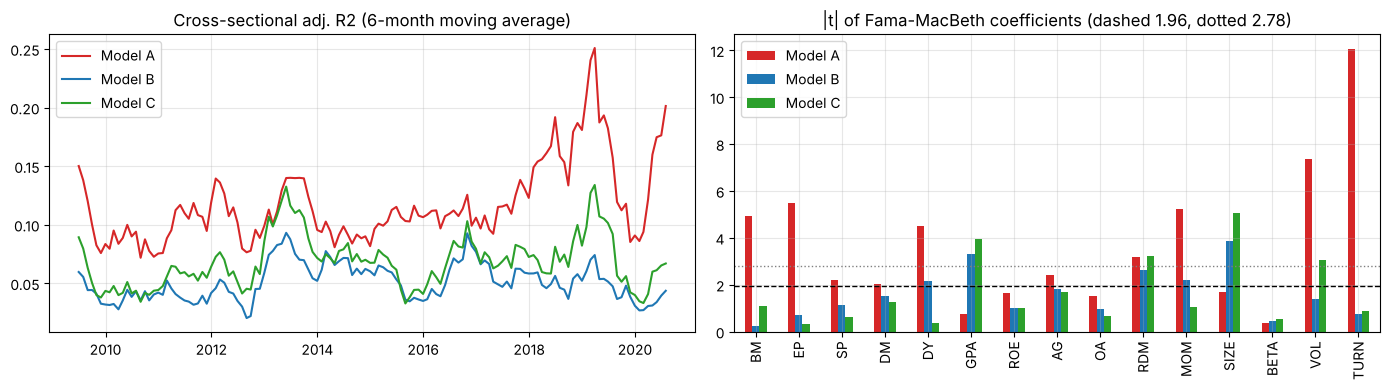

In [10]:
# 월별 횡단면 adj.R2 의 시계열 비교
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for m, c in zip('ABC', ['tab:red', 'tab:blue', 'tab:green']):
    ax[0].plot(FM[m]['adjR2'].rolling(6).mean(), label=f'Model {m}', color=c)
ax[0].set_title('Cross-sectional adj. R2 (6-month moving average)'); ax[0].legend(); ax[0].grid(alpha=.3)
t_abs = pd.DataFrame({f'Model {m}': SUM[m]['t'].drop('const').abs() for m in 'ABC'})
t_abs.plot.bar(ax=ax[1], color=['tab:red', 'tab:blue', 'tab:green'])
ax[1].axhline(1.96, color='k', ls='--', lw=1); ax[1].axhline(2.78, color='gray', ls=':', lw=1)
ax[1].set_title('|t| of Fama-MacBeth coefficients (dashed 1.96, dotted 2.78)'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

### 질문 1. 모형의 성과는 어떻게 변하였는가?

| | 평균 adj.$R^2$ | $\lvert t\rvert>1.96$ 인 변수 (15개 중) |
|---|---|---|
| A: 동시점 | **12.0%** | 10개 (BM, EP, SP, DM, DY, AG, RDM, MOM, VOL, TURN) |
| B: 16개월 시차 | **5.1%** | 5개 (DY, GPA, RDM, MOM, SIZE) |
| C: 회계 t−16 + 시장 t−1 | **6.9%** | 4개 (GPA, RDM, SIZE, VOL) |

- 설명변수를 16개월 전으로 바꾸면 **설명력이 절반 이하로 떨어지고**(12.0% → 5.1%), 유의한 변수도 10개에서 5개로 줄어듭니다.
- 시장자료만 1개월 전으로 당긴 모형 C 는 6.9% 로 B 보다 조금 높지만 A 에는 크게 못 미칩니다. 즉 A 의 성과 대부분은 "같은 달 정보"에서 나온 것이지 예측력이 아닙니다.
- 주의할 점: 예측모형의 횡단면 $R^2$ 5~7% 도 진짜 예측력이라고 볼 수 없습니다. 매월 계수를 새로 추정하므로, 부호가 달마다 바뀌는 변수(베타·변동성 등 위험노출 변수)도 $R^2$ 를 높이기 때문입니다. 사전에 쓸 수 있는 예측력은 **평균 계수의 t-값**으로 판단해야 합니다.

In [11]:
############################################################################################
# (2) 단변량 Fama-MacBeth 회귀: 변수 하나씩의 설명력 (평균 R2) 과 유의성
uni = {}
for m in 'ABC':
    Z = prep(CH[m], REG_VARS, winsor=True)
    rows = {}
    for k in REG_VARS:
        f = fama_macbeth(Z, [k])
        c, t = nw_t(f[k])
        rows[k] = [c, t, f['R2'].mean() * 100]
    uni[m] = pd.DataFrame(rows, index=['coef', 't', 'R2(%)']).T
uni_tab = pd.concat({MODEL_NAME[m]: uni[m] for m in 'ABC'}, axis=1)
uni_tab.insert(0, '분류', pd.Series(CATEGORY))
uni_tab

분류 A: 동시점 A(t)              B: 전체 16개월 시차 A(t-16)              C: 회계 t-16 + 시장 t-1             
                              coef      t R2(%)                  coef      t R2(%)                coef      t R2(%)
BM               Value      -1.112 -9.284 1.420                 0.193  1.876 0.751               0.276  2.467 0.967
EP               Value       0.657  5.634 1.208                -0.149 -1.326 0.804              -0.152 -1.496 0.799
SP               Value      -0.773 -9.040 0.890                 0.185  2.115 0.594               0.223  2.270 0.761
DM               Value      -0.671 -7.322 0.942                -0.073 -0.882 0.593              -0.016 -0.168 0.808
DY               Value      -0.698 -5.712 0.873                -0.078 -0.753 0.633               0.037  0.361 0.716
GPA      Profitability       0.403  4.475 0.781                 0.144  1.765 0.661               0.144  1.765 0.661
ROE      Profitability       0.649  4.628 1.333                -0.229 -1.904 0.853              -0.229 -1.904 0.853
AG          Investment       0.541  6.619 0.601                -0.186 -2.776 0.399              -0.186 -2.776 0.399
OA          Investment       0.139  2.098 0.297                -0.044 -0.694 0.271              -0.044 -0.694 0.271
RDM         Intangible      -0.453 -5.059 0.544                 0.325  3.759 0.555               0.365  4.147 0.546
MOM           Momentum      -0.017 -0.106 1.908                -0.194 -2.377 0.550               0.036  0.225 1.672
SIZE  Trading friction       0.214  1.706 1.175                -0.587 -4.065 1.365              -0.656 -4.423 1.308
BETA  Trading friction      -0.029 -0.159 3.339                -0.126 -1.259 0.945              -0.037 -0.300 1.287
VOL   Trading friction       0.399  2.092 1.982                 0.050  0.379 1.121               0.008  0.054 1.434
TURN  Trading friction       2.011  9.273 4.030                 0.003  0.029 0.978               0.072  0.512 1.692

In [12]:
# 모형 A 에서의 설명력 순위와 모형 B, C 에서의 설명력 순위 비교
rank = pd.DataFrame({f'R2 rank {m}': uni[m]['R2(%)'].rank(ascending=False) for m in 'ABC'}).astype(int)
rank['|t| A'] = uni['A']['t'].abs(); rank['|t| B'] = uni['B']['t'].abs(); rank['|t| C'] = uni['C']['t'].abs()
print(rank.sort_values('R2 rank A').to_string())
print('\n단변량 R2 의 순위상관 (Spearman):')
print(pd.DataFrame({m: uni[m]['R2(%)'] for m in 'ABC'}).corr(method='spearman').to_string())

      R2 rank A  R2 rank B  R2 rank C  |t| A  |t| B  |t| C
TURN          1          3          1  9.273  0.029  0.512
BETA          2          4          5  0.159  1.259  0.300
VOL           3          2          3  2.092  0.379  0.054
MOM           4         13          2  0.106  2.377  0.225
BM            5          7          6  9.284  1.876  2.467
ROE           6          5          7  4.628  1.904  1.904
EP            7          6          9  5.634  1.326  1.496
SIZE          8          1          4  1.706  4.065  4.423
DM            9         11          8  7.322  0.882  0.168
SP           10         10         10  9.040  2.115  2.270
DY           11          9         11  5.712  0.753  0.361
GPA          12          8         12  4.475  1.765  1.765
AG           13         14         14  6.619  2.776  2.776
RDM          14         12         13  5.059  3.759  4.147
OA           15         15         15  2.098  0.694  0.694

단변량 R2 의 순위상관 (Spearman):
      A     B     C
A 1.000 0

### 질문 2. 어떤 변수가 예측력이 있는 것으로 나타나는가?

다변량 예측회귀(모형 B·C)에서 평균 계수가 유의한 변수는 다음과 같습니다.

| 변수 | B 계수 (t) | C 계수 (t) | 해석 |
|---|---|---|---|
| **SIZE** | −0.53 (−3.88) | −0.66 (−5.04) | 소형주가 높은 수익률 (규모효과). 두 모형 모두 다중검정 기준 2.78 통과 |
| **GPA** | +0.23 (3.29) | +0.28 (3.95) | 매출총이익률이 높은 기업이 높은 수익률 (수익성). 2.78 통과 |
| **RDM** | +0.22 (2.65) | +0.26 (3.23) | R&D 집약도가 높은 기업이 높은 수익률 (무형자산) |
| VOL | −0.11 (−1.39) | −0.23 (−3.04) | 저변동성 효과. 최근(t−1) 변동성일 때만 유의 |
| DY, MOM | −0.15 (−2.16), −0.16 (−2.18) | 유의하지 않음 | B 에서만 약하게 유의. 16개월 전 모멘텀의 음(−)의 계수는 장기 반전에 해당 |

단변량 회귀에서는 여기에 BM(+), SP(+), AG(−) 가 추가로 유의합니다(|t| 2.1~2.8). 다변량에서 사라지는 것은 SIZE·GPA 와 정보가 겹치기 때문입니다.
BETA 는 어느 모형에서도 유의하지 않아, 과제 I 의 CAPM 검증 결과(베타의 가격이 0 과 다르지 않음)와 일치합니다.

### 질문 3. 첫 번째 회귀에서 설명력이 높은 변수가 예측모형에서도 설명력이 높은가?

**대체로 그렇지 않습니다.**

| 변수 | A 의 t | B 의 t | |
|---|---|---|---|
| TURN | **12.07** | 0.73 | 동시점에서 가장 강했으나 예측력 없음 |
| VOL | **−7.34** | −1.39 | 〃 |
| EP | **5.47** | 0.73 | 〃 |
| MOM | **−5.24** | −2.18 | 크게 약화 |
| BM | **−4.92** | 0.24 | 부호까지 반대로 (동시점 −, 예측 +) |
| SIZE | −1.70 | **−3.88** | 반대로 동시점에서는 약하고 예측에서 강함 |
| GPA | −0.75 | **3.29** | 〃 |

- 동시점에서 유의했던 10개 변수 중 16개월 시차 모형에서도 유의한 것은 DY, RDM, MOM 3개뿐이고, 그중 RDM 은 부호가 반대입니다(A −0.33 → B +0.22).
- 단변량 $R^2$ 순위는 A 와 B 사이 순위상관이 0.69 로 어느 정도 유지됩니다. TURN·BETA·VOL 같은 거래 관련 변수는 어느 시점에서나 $R^2$ 가 높지만 t-값은 낮습니다. 이들은 수익률의 **횡단면 분산**(달마다 부호가 바뀌는 위험노출)을 설명할 뿐 **평균 수익률의 차이**는 설명하지 못한다는 뜻입니다. "설명력($R^2$)"과 "예측력(평균 프리미엄)"은 다른 개념입니다.

In [13]:
############################################################################################
# (3) 예측력의 원천: 모형 A 의 설명력이 "동시점 가격정보"에서 오는지 확인
#     가격비율 변수(BM, EP, SP, DM, SIZE)의 분모만 전월(t-1) 시가총액으로 바꾸고, 나머지는 동시점 그대로 둔 모형 A'
CH_A2 = build_chars(0, 0, 1)
for k in ['DY', 'BETA', 'VOL', 'TURN', 'MOM', 'GPA', 'ROE', 'AG', 'OA']:
    CH_A2[k] = CH['A'][k]
FM_A2 = fama_macbeth(prep(CH_A2, REG_VARS), REG_VARS)
cmp_src = pd.concat({'A: 분모 ME(t)': SUM['A'], "A': 분모 ME(t-1)": fm_summary(FM_A2, REG_VARS)}, axis=1)
print('평균 adj.R2  A:', round(FM['A']['adjR2'].mean(), 4), " A':", round(FM_A2['adjR2'].mean(), 4))
cmp_src.loc[['BM', 'EP', 'SP', 'DM', 'SIZE', 'TURN', 'VOL', 'MOM']]

평균 adj.R2  A: 0.1199  A': 0.1267


A: 분모 ME(t)        A': 분모 ME(t-1)       
            coef      t           coef      t
BM        -0.686 -4.919          1.165  8.445
EP         0.820  5.466          0.697  5.218
SP        -0.449 -2.206         -0.087 -0.535
DM        -0.135 -2.042          0.007  0.089
SIZE      -0.226 -1.700         -0.346 -3.161
TURN       2.328 12.067          2.686 14.316
VOL       -0.772 -7.341         -0.456 -4.259
MOM       -0.886 -5.240         -0.504 -3.374

위 실험에서 가격비율 변수의 분모(시가총액)만 한 달 전 값으로 바꿔도 BM 의 계수가 **−0.69 (t = −4.9) → +1.17 (t = 8.4)** 로 뒤집힙니다.
- 분모가 $ME_t$ 일 때의 음(−)의 계수는 "이번 달 주가가 오르면 $ME_t$ 가 커져 BM 이 낮아진다"는 **기계적 관계**입니다.
- 분모를 $ME_{t-1}$ 로 바꾼 뒤의 매우 강한 양(+)의 계수는 분자인 자기자본이 **아직 공시되지 않은 당해 회계연도 값**(look-ahead)이기 때문입니다. 올해 이익이 많이 나서 자기자본이 늘어날 기업을 미리 아는 셈입니다.

In [14]:
############################################################################################
# (4) 이상치(outliers)를 제거하지 않을 경우: winsorize 없이 동일한 회귀
FM_raw, SUM_raw = {}, {}
for m in 'ABC':
    Z = prep(CH[m], REG_VARS, winsor=False)
    FM_raw[m] = fama_macbeth(Z, REG_VARS)
    SUM_raw[m] = fm_summary(FM_raw[m], REG_VARS)

out_tab = pd.concat({(MODEL_NAME[m], w): s['t'] for m in 'ABC' for w, s in [('winsor', SUM[m]), ('raw', SUM_raw[m])]}, axis=1).drop('const')
perf_raw = pd.DataFrame({MODEL_NAME[m]: [FM[m]['adjR2'].mean(), FM_raw[m]['adjR2'].mean()] for m in 'ABC'}, index=['adj.R2 winsor', 'adj.R2 raw']).T
print(perf_raw.to_string()); print()
print('=== Newey-West t-값 비교 (winsorize 적용 vs 미적용) ===')
out_tab

                       adj.R2 winsor  adj.R2 raw
A: 동시점 A(t)                    0.120       0.125
B: 전체 16개월 시차 A(t-16)          0.051       0.055
C: 회계 t-16 + 시장 t-1            0.069       0.073

=== Newey-West t-값 비교 (winsorize 적용 vs 미적용) ===


A: 동시점 A(t)        B: 전체 16개월 시차 A(t-16)        C: 회계 t-16 + 시장 t-1       
          winsor    raw                winsor    raw              winsor    raw
BM        -4.919 -4.379                 0.235  0.168               1.095  0.963
EP         5.466  4.523                 0.726 -0.876              -0.316 -1.936
SP        -2.206 -2.315                 1.122  1.093               0.615  0.824
DM        -2.042 -1.168                -1.511 -1.879              -1.264 -1.819
DY        -4.487 -2.063                -2.156 -1.405              -0.347  0.330
GPA       -0.750  0.767                 3.287  3.281               3.948  3.554
ROE        1.642  1.658                -0.994 -0.539              -0.987 -0.197
AG         2.399  0.660                -1.832 -1.958              -1.684 -1.566
OA         1.499  2.371                -0.949 -1.243              -0.642 -0.774
RDM       -3.184 -1.383                 2.645  2.750               3.226  3.012
MOM       -5.240 -5.376                -2.179 -1.418               1.038  0.751
SIZE      -1.700 -0.600                -3.880 -3.690              -5.041 -4.718
BETA      -0.354 -1.220                -0.436 -0.838               0.548  0.068
VOL       -7.341 -5.755                -1.390 -0.748              -3.038 -2.833
TURN      12.067 12.147                 0.728  0.059               0.880  0.912

In [15]:
# 이상치의 크기: winsorize 전 원자료의 왜도/첨도 (모형 C 기준, 전체 기간 pooled)
desc = pd.DataFrame({k: CH['C'][k].loc[START:END].stack().agg(['skew', 'kurt', 'min', 'median', 'max']) for k in REG_VARS}).T
desc

,skew,kurt,min,median,max
BM,2.956,29.264,0.002,1.106,28.502
EP,-25.978,"1,351.016",-55.009,0.056,26.090
SP,4.190,36.323,0.000,1.939,90.103
DM,7.727,116.531,-0.048,1.063,212.949
DY,9.520,314.844,0.000,1.080,90.500
GPA,3.138,28.408,-2.310,0.170,2.681
ROE,-52.370,"3,155.633",-265.657,0.057,37.478
AG,89.705,"8,045.083",-0.963,0.051,"1,528,119.571"
OA,-11.082,352.820,-5.854,-0.031,1.537
RDM,20.283,"1,002.876",0.000,0.011,4.256


### 질문 5. 이상치(outliers)를 제거하지 않을 경우에도 같은 결과가 나오는가?

**핵심 결론은 유지되지만, 여러 변수의 유의성이 달라집니다.**

- **강건한 결과**: 예측모형의 SIZE(C: −5.04 → −4.72), GPA(3.95 → 3.55), RDM(3.23 → 3.01), VOL(−3.04 → −2.83) 과 동시점 모형의 TURN, MOM, BM 은 winsorize 여부와 무관하게 유의합니다.
- **이상치에 민감한 결과**:
  - 모형 A: DY(−4.49 → −2.06), RDM(−3.18 → −1.38, 유의성 상실), AG(2.40 → 0.66, 유의성 상실), DM(−2.04 → −1.17, 유의성 상실), OA(1.50 → 2.37, 새로 유의)
  - 모형 B: DY(−2.16 → −1.41), MOM(−2.18 → −1.42) 가 유의성을 잃음
  - 모형 C: EP(−0.32 → −1.94) 가 유의수준 경계까지 변함
- **원인**: 원자료의 분포가 극단적입니다. AG 의 최댓값은 약 153만(자산이 0 에 가까웠던 기업), ROE 의 최솟값은 −266, BETA 의 첨도는 1만 4천을 넘습니다. 비율 변수는 분모가 0 에 가까워지면 값이 폭발하고, 이런 관측치 몇 개가 표준화의 평균·표준편차와 OLS 계수를 좌우합니다.
- SIZE 와 TURN 처럼 로그를 취한 변수는 분포가 정규분포에 가까워(첨도 0.2, 0.9) winsorize 의 영향을 거의 받지 않습니다.
- 평균 adj.$R^2$ 는 이상치를 그대로 둘 때 오히려 0.4~0.5%p 높지만, 이는 소수의 극단값을 맞춘 결과이므로 모형이 더 좋다는 뜻이 아닙니다.

In [16]:
############################################################################################
# (6) 특성의 지속성: 동일 기업의 특성 순위가 16개월 뒤에도 유지되는가?  (t 시점과 t-16 시점 특성의 횡단면 순위상관 평균)
pers = pd.Series({k: CH['A'][k].loc[START:END].corrwith(CH['A'][k].shift(LAGS).loc[START:END], axis=1, method='spearman').mean()
                  for k in REG_VARS}, name='rank corr(A_t, A_t-16)')
pers = pd.concat([pers, SUM['A']['t'].drop('const').rename('t (Model A)'), SUM['B']['t'].drop('const').rename('t (Model B)')], axis=1)
pers.sort_values('rank corr(A_t, A_t-16)', ascending=False)

,"rank corr(A_t, A_t-16)",t (Model A),t (Model B)
SIZE,0.948,-1.700,-3.880
VOL,0.886,-7.341,-1.390
DM,0.885,-2.042,-1.511
SP,0.871,-2.206,1.122
GPA,0.865,-0.750,3.287
RDM,0.832,-3.184,2.645
BM,0.797,-4.919,0.235
BETA,0.788,-0.354,-0.436
DY,0.748,-4.487,-2.156
TURN,0.607,12.067,0.728


### 질문 4. 예측력이 높은 설명변수의 예측력은 어디에서 오는가?

**(1) 동시점 모형의 "설명력"은 예측력이 아니라 정보의 동시성에서 옵니다.**
- *가격의 기계적 효과*: BM, EP, SP, DM 은 분모가 $t$ 시점 시가총액이라 당월 수익률이 변수 안에 들어 있습니다(위 A′ 실험).
- *회계정보의 선행 사용*: 회계연도 $Y$ 값이 $Y$년 1월부터 들어가므로 AG(+2.4), ROE, EP(+5.5) 는 "올해 실적이 좋을 기업"을 미리 알고 설명하는 것입니다. 16개월 시차를 주면 AG 는 부호가 음(−)으로 바뀌고 EP·ROE 는 사라집니다.
- *거래량·변동성과 수익률의 동시 관계*: 주가가 급등하는 달에 거래가 몰리므로 TURN 의 t-값이 12 를 넘지만, 한 달만 지나도 사라집니다.

**(2) 16개월이 지나도 남는 예측력은 "천천히 변하는 특성"에서 옵니다.**
바로 위 표를 보면 예측회귀에서 유의한 SIZE(순위상관 0.95), GPA(0.87), RDM(0.83) 은 모두 16개월 뒤에도 기업 순위가 거의 그대로인 특성입니다. 반면 MOM(−0.03), OA(−0.05), AG(0.19) 처럼 빨리 변하는 신호는 16개월 전 값이 현재 상태를 알려주지 못해 동시점에서의 관계가 사라지거나 뒤집힙니다. 다만 VOL(0.89), DM(0.89), SP(0.87) 처럼 지속성이 높아도 유의하지 않은 변수가 있으므로, 지속성은 필요조건일 뿐 충분조건은 아닙니다. 따라서 모형 B 의 예측력은 "16개월 전 정보" 자체가 아니라 그 특성이 대리하는 **기업의 지속적 속성**에 대한 보상입니다.

**(3) 그 지속적 속성이 왜 보상받는가** 에 대한 해석은 다음과 같습니다.
- **SIZE**: 소형주의 낮은 유동성·높은 거래비용과 정보 불확실성에 대한 보상. 논문도 한국시장 이상현상의 상당 부분이 microcap 에서 나온다고 강조합니다. 다만 이 데이터는 표본 종료 시점에 존재하는 종목 위주여서, 상장폐지된 소형주가 빠진 **생존편의**가 규모효과를 과대평가했을 가능성이 큽니다.
- **GPA**: 수익성이 높은 기업의 높은 기대수익률(Novy-Marx, 2013). 투자자가 이익의 지속성을 과소평가한다는 설명과, q-이론에 따른 위험 보상이라는 설명이 있습니다.
- **RDM**: R&D 는 비용 처리되어 장부에 자산으로 잡히지 않으므로 시장이 무형자산의 가치를 과소평가한다는 설명(Chan et al., 2001)과, R&D 성과의 불확실성에 대한 위험 프리미엄이라는 설명이 있습니다.
- **VOL**: 복권형 주식 선호와 공매도 제약으로 고변동성 주식이 고평가된다는 설명. 최근 변동성(t−1)일 때만 유의합니다.

In [17]:
############################################################################################
# (5) 간결한 예측모형: 모형 C 에서 유의한 변수만 사용
sel = SUM['C'].drop('const').query('abs(t) > 1.96').index.tolist()
print('선택된 변수:', sel)
FM_sel = fama_macbeth(prep(CH['C'], sel), sel)
print('평균 adj.R2 (전체 변수):', round(FM['C']['adjR2'].mean(), 4), '| (선택 변수):', round(FM_sel['adjR2'].mean(), 4))
fm_summary(FM_sel, sel)

선택된 변수: ['GPA', 'RDM', 'SIZE', 'VOL']


평균 adj.R2 (전체 변수): 0.0685 | (선택 변수): 0.0289


,coef,t
const,1.299,3.028
GPA,0.245,3.178
RDM,0.289,3.311
SIZE,-0.726,-5.183
VOL,-0.139,-1.049


**모형 수립 결론.** 개별주식의 월수익률을 사전에 설명하는 변수는 SIZE(−), GPA(+), RDM(+) 세 가지로 압축됩니다. VOL 은 다른 변수와 함께 있을 때만 유의하고 단독으로는 유의하지 않습니다(t = −1.05).
변수를 4개로 줄이면 평균 adj.$R^2$ 는 6.9% → 2.9% 로 떨어지는데, 빠진 설명력은 대부분 평균 프리미엄이 없는 위험노출 변수(BETA, TURN, MOM 등)의 몫입니다.

## 3. 요인의 계산: 헤지포트폴리오

- **구성**: 매월 말, 그 시점에 알 수 있는 정보(회계 $t-16$, 시장 $t-1$)로 종목을 5분위로 나누고 다음 달 수익률을 계산합니다. 헤지포트폴리오는 **High(5분위) 매수 − Low(1분위) 매도** 입니다.
- **가중방식**: 전월 말 시가총액 가중(VW)과 동일가중(EW)을 모두 계산합니다. 논문은 microcap 의 영향을 줄이기 위해 VW 를 기본으로 하고 EW 와 비교합니다.
- **검정**: 평균수익률의 Newey-West t-값, 그리고 시장요인(KOSPI 초과수익률)으로 회귀한 CAPM 알파.
- **기간**: 2009-01 ~ 2020-07 (139개월). 논문(10분위, 2000-01 ~ 2019-06, KOSPI+KOSDAQ)과 분위 수·기간·표본이 다릅니다.

In [18]:
############################################################################################
# 요인의 계산: 헤지포트폴리오 (High - Low)
#   t-1월 말에 알 수 있는 정보(회계 t-16, 시장 t-1)로 5분위 포트폴리오를 만들고 t월 수익률을 계산, 매월 재구성
ME_lag = ME.shift(1)

def sort_portfolios(char, n=N_PORT, weight='vw', start=START, end=END):
    rows = {}
    for t in R.loc[start:end].index:
        x, y, w = char.loc[t], R.loc[t], ME_lag.loc[t]
        ok = x.notna() & y.notna() & w.notna()
        if ok.sum() < MIN_STOCKS:
            continue
        x, y, w = x[ok], y[ok], w[ok]
        q = pd.qcut(x.rank(method='first'), n, labels=False)
        if weight == 'ew':
            rows[t] = y.groupby(q).mean()
        else:
            rows[t] = (y * w).groupby(q).sum() / w.groupby(q).sum()
    P = pd.DataFrame(rows).T
    P.columns = ['Low'] + [str(i) for i in range(2, n)] + ['High']
    P['H-L'] = P['High'] - P['Low']
    return P

def factor_stats(hl):
    hl = hl.dropna()
    mean, t = nw_t(hl)
    X = sm.add_constant(MKT.reindex(hl.index))
    capm = sm.OLS(hl, X, missing='drop').fit(cov_type='HAC', cov_kwds={'maxlags': NW_LAGS})
    cum = ((1 + hl / 100).prod() - 1) * 100
    return pd.Series({'평균(%/월)': mean, 't': t, 'CAPM alpha': capm.params['const'], 't(alpha)': capm.tvalues['const'],
                      'beta_MKT': capm.params['MKT'], '연 Sharpe': hl.mean() / hl.std() * np.sqrt(12), '누적수익률(%)': cum})

FACTOR_VARS = ['BM', 'EP', 'SP', 'DM', 'DY', 'GPA', 'ROE', 'OPA', 'AG', 'OA', 'RDM', 'MOM', 'SIZE', 'BETA', 'VOL', 'TURN', 'DTV']
PORT = {w: {k: sort_portfolios(CH['C'][k], weight=w) for k in FACTOR_VARS} for w in ['vw', 'ew']}

In [19]:
# 5분위 포트폴리오 평균수익률 (가치가중)
q_tab = pd.DataFrame({k: PORT['vw'][k].mean() for k in FACTOR_VARS}).T
q_tab.insert(0, '분류', pd.Series(CATEGORY))
print('=== 가치가중(VW) 5분위 포트폴리오 월평균 수익률 (%) ===')
q_tab

=== 가치가중(VW) 5분위 포트폴리오 월평균 수익률 (%) ===


,분류,Low,2,3,4,High,H-L
BM,Value,0.670,0.791,0.875,0.658,0.981,0.311
EP,Value,0.480,0.698,0.681,0.801,1.033,0.554
SP,Value,0.657,0.804,0.597,0.558,0.994,0.337
DM,Value,0.858,1.010,0.302,0.443,0.628,-0.230
DY,Value,0.924,0.942,0.259,0.887,0.617,-0.308
GPA,Profitability,0.578,0.489,0.474,0.687,1.158,0.580
ROE,Profitability,0.775,0.735,0.730,0.689,0.826,0.051
OPA,Profitability,0.594,0.649,0.745,0.246,1.044,0.450
AG,Investment,0.594,0.543,0.759,0.757,0.551,-0.043
OA,Investment,0.964,1.110,0.666,0.581,0.522,-0.442


In [20]:
# 헤지포트폴리오(High - Low) 수익률이 0 과 다른지 검정
stats = {w: pd.DataFrame({k: factor_stats(PORT[w][k]['H-L']) for k in FACTOR_VARS}).T for w in ['vw', 'ew']}
f_tab = pd.concat({'가치가중 (VW)': stats['vw'], '동일가중 (EW)': stats['ew']}, axis=1)
f_tab.insert(0, '분류', pd.Series(CATEGORY))
f_tab

분류 가치가중 (VW)                                                       동일가중 (EW)                                                      
                         평균(%/월)      t CAPM alpha t(alpha) beta_MKT 연 Sharpe 누적수익률(%)   평균(%/월)      t CAPM alpha t(alpha) beta_MKT 연 Sharpe 누적수익률(%)
BM               Value     0.311  0.688      0.296    0.633    0.036    0.192   23.971     0.715  2.158      0.682    2.002    0.075    0.643  143.250
EP               Value     0.554  1.510      0.552    1.519    0.003    0.411   85.546    -0.218 -0.748     -0.189   -0.647   -0.067   -0.239  -31.076
SP               Value     0.337  0.741      0.168    0.386    0.391    0.241   36.108     0.699  2.254      0.564    1.949    0.313    0.649  139.456
DM               Value    -0.230 -0.564     -0.386   -1.076    0.362   -0.162  -38.361     0.349  1.149      0.181    0.707    0.390    0.314   46.780
DY               Value    -0.308 -0.731     -0.229   -0.567   -0.181   -0.243  -43.216    -0.141 -0.434     -0.046   -0.141   -0.221   -0.145  -24.095
GPA      Profitability     0.580  1.887      0.709    2.411   -0.298    0.424   91.556     0.509  1.972      0.597    2.397   -0.203    0.553   88.976
ROE      Profitability     0.051  0.127      0.169    0.449   -0.272    0.037   -9.030    -0.607 -2.021     -0.569   -1.911   -0.088   -0.624  -60.448
OPA      Profitability     0.450  1.250      0.590    1.852   -0.324    0.345   61.520    -0.308 -1.035     -0.237   -0.828   -0.163   -0.314  -39.931
AG          Investment    -0.043 -0.139     -0.016   -0.054   -0.062   -0.037  -15.798    -0.710 -3.533     -0.705   -3.596   -0.012   -0.945  -64.613
OA          Investment    -0.442 -0.878     -0.519   -1.072    0.177   -0.277  -56.376    -0.092 -0.522     -0.115   -0.657    0.054   -0.148  -14.746
RDM         Intangible     1.253  2.411      1.127    2.188    0.291    0.694  333.697     1.248  5.012      1.175    5.179    0.170    1.710  437.503
MOM           Momentum     0.602  1.029      0.761    1.387   -0.367    0.314   69.604     0.192  0.418      0.280    0.642   -0.203    0.142   12.051
SIZE  Trading friction    -1.743 -3.746     -1.733   -3.797   -0.024   -1.267  -92.643    -2.130 -4.742     -2.123   -4.844   -0.014   -1.673  -95.654
BETA  Trading friction     0.098  0.199     -0.154   -0.349    0.585    0.063   -6.542    -0.161 -0.435     -0.443   -1.419    0.653   -0.129  -29.663
VOL   Trading friction    -0.395 -0.660     -0.540   -0.954    0.334   -0.207  -57.302     0.148  0.347     -0.069   -0.171    0.502    0.111    6.028
TURN  Trading friction     0.634  1.277      0.434    0.941    0.464    0.371   89.637     0.333  0.846      0.131    0.342    0.467    0.247   36.915
DTV   Trading friction    -0.265 -0.895     -0.393   -1.433    0.295   -0.288  -35.587    -1.391 -4.855     -1.514   -5.697    0.285   -1.380  -86.928

In [21]:
# 유의성 요약: |t| > 1.96 (단일검정), |t| > 2.78 (다중검정, Harvey et al. 2016)
sig = pd.DataFrame({(w, c): [(stats[w]['t'].abs() > c).sum(), (stats[w]['t(alpha)'].abs() > c).sum()]
                    for w in ['vw', 'ew'] for c in [1.96, 2.78]}, index=['H-L 평균', 'CAPM alpha']).T
sig.index.names = ['가중', '|t| 기준']
print(f'전체 {len(FACTOR_VARS)}개 특성 중 유의한 개수'); print(sig.to_string())

전체 17개 특성 중 유의한 개수
           H-L 평균  CAPM alpha
가중 |t| 기준                    
vw 1.960        2           3
   2.780        1           1
ew 1.960        8           6
   2.780        4           4


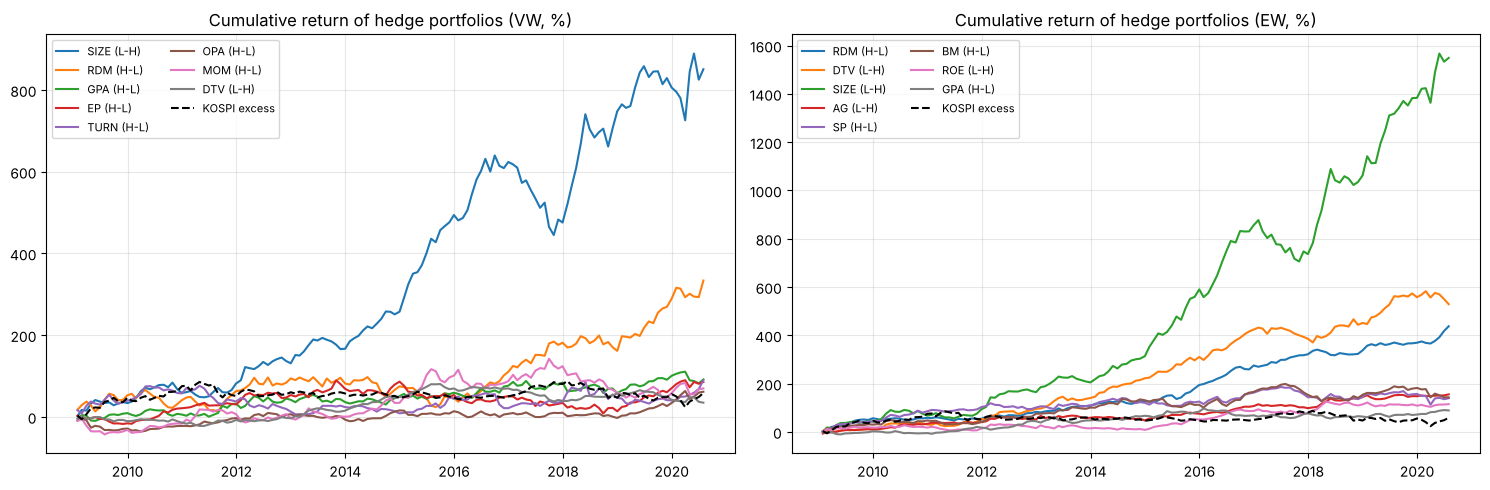

In [22]:
# 누적수익률: 수익률이 양(+)이 되도록 방향을 맞춘 헤지포트폴리오 (평균이 음수이면 Low - High)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=False)
for ax, w in zip(axes, ['vw', 'ew']):
    top = stats[w]['t'].abs().sort_values(ascending=False).index[:8]
    for k in top:
        hl = PORT[w][k]['H-L'].dropna()
        sgn = np.sign(hl.mean())
        ax.plot(((1 + sgn * hl / 100).cumprod() - 1) * 100, label=f"{k} ({'H-L' if sgn > 0 else 'L-H'})")
    mk = MKT.loc[START:END]
    ax.plot(((1 + mk / 100).cumprod() - 1) * 100, 'k--', lw=1.5, label='KOSPI excess')
    ax.set_title(f'Cumulative return of hedge portfolios ({w.upper()}, %)'); ax.legend(fontsize=8, ncol=2); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [23]:
# 방향을 맞춘(수익이 나는 쪽을 매수) 헤지포트폴리오의 누적수익률과 연환산 수익률
def directed(w):
    rows = {}
    for k in FACTOR_VARS:
        hl = PORT[w][k]['H-L'].dropna(); sgn = np.sign(hl.mean()); g = (1 + sgn * hl / 100)
        rows[k] = ['H-L' if sgn > 0 else 'L-H', (g.prod() - 1) * 100, (g.prod() ** (12 / len(g)) - 1) * 100, abs(stats[w].loc[k, 't'])]
    return pd.DataFrame(rows, index=['방향', '누적수익률(%)', '연환산(%)', '|t|']).T
pd.concat({'가치가중 (VW)': directed('vw'), '동일가중 (EW)': directed('ew')}, axis=1).sort_values(('동일가중 (EW)', '|t|'), ascending=False)

가치가중 (VW)                       동일가중 (EW)                       
            방향 누적수익률(%) 연환산(%)   |t|        방향  누적수익률(%) 연환산(%)   |t|
RDM        H-L  333.697 13.503 2.411       H-L   437.503 15.626 5.012
DTV        L-H   34.718  2.606 0.895       L-H   528.980 17.205 4.855
SIZE       L-H  850.931 21.463 3.746       L-H 1,548.738 27.373 4.742
AG         L-H   -5.008 -0.443 0.139       L-H   155.486  8.435 3.533
SP         H-L   36.108  2.697 0.741       H-L   139.456  7.830 2.254
BM         H-L   23.971  1.872 0.688       H-L   143.250  7.976 2.158
ROE        H-L   -9.030 -0.814 0.127       L-H   114.959  6.830 2.021
GPA        H-L   91.556  5.772 1.887       H-L    88.976  5.648 1.972
DM         L-H   15.862  1.279 0.564       H-L    46.780  3.369 1.149
OPA        H-L   61.520  4.226 1.250       L-H    41.764  3.059 1.035
TURN       H-L   89.637  5.680 1.277       H-L    36.915  2.750 0.846
EP         H-L   85.546  5.481 1.510       L-H    26.434  2.046 0.748
OA         L-H   49.717  3.546 0.878       L-H    10.073  0.832 0.522
BETA       H-L   -6.542 -0.582 0.199       L-H     9.607  0.795 0.435
DY         L-H   34.662  2.603 0.731       L-H    12.515  1.023 0.434
MOM        H-L   69.604  4.666 1.029       H-L    12.051  0.987 0.418
VOL        L-H   27.389  2.112 0.660       H-L     6.028  0.507 0.347

### 헤지포트폴리오는 0 과 다른 수익률을 가져다주는가?

**가치가중(VW)**: 17개 중 $|t|>1.96$ 은 2개, $|t|>2.78$ 은 1개뿐입니다.
- **SIZE**: H−L = −1.74%/월 (t = −3.75). 소형주 매수·대형주 매도 시 월 1.74%
- **RDM**: +1.25%/월 (t = 2.41). 누적수익률 334%
- CAPM 알파 기준으로는 GPA(알파 0.71%, t = 2.41)가 추가됩니다.
- 가치(BM 0.31%, t = 0.69), 모멘텀(0.60%, t = 1.03), 변동성·거래 관련 요인은 방향은 논문과 대체로 같지만 유의하지 않습니다.

**동일가중(EW)**: $|t|>1.96$ 이 8개, $|t|>2.78$ 이 4개로 늘어납니다.
- $|t|>2.78$: **RDM**(+1.25%, t = 5.01, 누적 438%), **DTV**(−1.39%, t = −4.86), **SIZE**(−2.13%, t = −4.74), **AG**(−0.71%, t = −3.53)
- $|t|>1.96$: SP(+0.70%, t = 2.25), BM(+0.72%, t = 2.16), ROE(−0.61%, t = −2.02), GPA(+0.51%, t = 1.97)

### 논문과의 비교

| | 논문 (2000–2019) | 본 분석 (2009–2020) |
|---|---|---|
| VW 에서 유의한 비율 | 148개 중 37.8% (1.96), 27.7% (2.78) | 17개 중 2개 (1.96), 1개 (2.78) |
| EW 로 바꾸면 | 수익률과 t-값이 커지고 유의한 이상현상이 늘어남 | 유의한 요인이 2개 → 8개 |
| R&D/시가 (Rdm) | VW 1.64% (t = 3.66), EW 1.46% (t = 5.60) | VW 1.25% (t = 2.41), EW 1.25% (t = 5.01) |
| 자산성장 (I/A) | VW 유의하지 않음, EW −1.53% (t = 4.48) | VW −0.04% (t = −0.14), EW −0.71% (t = −3.53) |
| 거래대금 (Dtv) | VW −2.10% (t = 5.10), EW −3.79% (t = 8.80) | VW −0.27% (t = −0.90), EW −1.39% (t = −4.86) |
| 가치 (Bm) | VW 1.49% (t = 4.15), KOSPI 만 1.19% (t = 2.94) | VW 0.31% (t = 0.69), EW 0.72% (t = 2.16) |
| 모멘텀 | 전체 표본에서는 유의, KOSPI 만으로는 2.78 기준 통과 0개 | 유의하지 않음 |
| 수익성 | 20개 중 1개만 유의 | GPA 만 경계선에서 유의 |

- 논문의 핵심 주장인 **"이상현상의 상당 부분은 microcap 에서 나오며, VW 와 EW 의 결과가 크게 다르다"** 는 이 데이터에서도 그대로 확인됩니다. BM, SP, AG, DTV 는 EW 에서만 유의합니다.
- RDM 이 가중방식과 무관하게 유의하다는 점, 투자(AG) 요인이 EW 에서만 나타난다는 점, 모멘텀이 대형주 중심 표본에서 약하다는 점도 논문과 일치합니다.
- 가치와 거래마찰 요인이 논문보다 약한 것은 표본기간(금융위기 이후)과 표본 구성(종목 수가 적고 KOSDAQ 소형주가 덜 포함됨), 5분위 사용의 차이로 보입니다.

### 이 거래전략을 구사할 경우 누적수익률은?

위 표와 그림이 수익이 나는 방향으로 매수·매도했을 때의 누적수익률입니다(2009-01 ~ 2020-07, 139개월, 거래비용 미반영). 같은 기간 KOSPI 초과수익률의 누적은 그림의 검은 점선입니다.
- **RDM** (고 R&D 매수 − 저 R&D 매도): VW 334% (연 13.5%), EW 438% (연 15.6%)
- **SIZE** (소형주 매수 − 대형주 매도): VW 851% (연 21.5%), EW 1,549% (연 27.4%). 생존편의와 거래비용 때문에 실제로 얻을 수 있는 수치로 보기는 어렵습니다.
- **DTV** (저거래대금 매수 − 고거래대금 매도): EW 529% (연 17.2%), VW 는 35% 에 그침
- **AG** (저성장 매수 − 고성장 매도): EW 155% (연 8.4%), VW 는 −5%
- **BM / SP** (가치주 매수): EW 143% / 139% (연 약 8%), VW 24% / 36%
- 통계적으로 유의한 전략은 누적수익률도 크고 경로가 비교적 꾸준합니다.
- 유의하지 않은 전략(MOM, TURN, VOL 등)은 누적수익률이 양(+)이더라도 특정 기간에 몰려 있어 변동이 큽니다.
- SIZE·DTV 전략은 소형·저유동성 주식을 매수하고 매월 재구성하므로, 실제로는 거래비용과 시장충격 때문에 이 수익률을 얻기 어렵습니다(논문도 Novy-Marx and Velikov, 2016 을 인용해 같은 점을 지적).

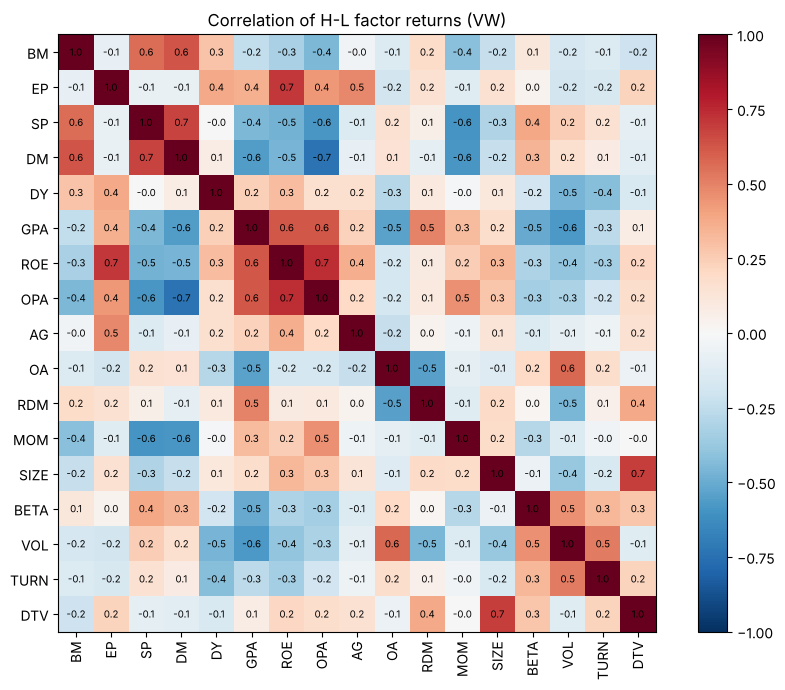

In [24]:
# 요인 수익률 간 상관관계 (가치가중, 방향 조정 없음)
F = pd.DataFrame({k: PORT['vw'][k]['H-L'] for k in FACTOR_VARS})
corr = F.corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.1f}', ha='center', va='center', fontsize=7)
plt.colorbar(im); ax.set_title('Correlation of H-L factor returns (VW)'); plt.tight_layout(); plt.show()

요인 수익률 간 상관을 보면 같은 범주 안에서 상관이 높습니다(가치 BM–SP–DM 0.56~0.68, 수익성 GPA–ROE–OPA 0.62~0.74, 거래마찰 BETA–VOL–TURN 0.34~0.52). 또 가치 요인과 수익성 요인은 서로 강한 음(−)의 상관(−0.25 ~ −0.74)을 보여, 가치주가 대체로 수익성이 낮은 기업이라는 점도 드러납니다. 논문 Table 7 의 주성분분석에서 범주 내 첫 번째 주성분의 설명비중이 높게 나온 것과 같은 현상으로, 17개 특성이 17개의 독립된 요인은 아니라는 뜻입니다.

In [25]:
############################################################################################
# 다요인 모형: 시장(MKT) + 규모(SMB) + 가치(HML) 요인을 직접 만들어 나머지 헤지포트폴리오를 설명하는지 검정
SMB = -PORT['vw']['SIZE']['H-L']          # Small - Big
HML = PORT['vw']['BM']['H-L']             # High BM - Low BM
FF3 = pd.concat([MKT, SMB.rename('SMB'), HML.rename('HML')], axis=1).loc[START:END].dropna()
print('요인 평균 (%/월) 과 t-값'); print(pd.DataFrame({k: nw_t(FF3[k]) for k in FF3}, index=['mean', 't']).T.to_string()); print()

rows = {}
for k in FACTOR_VARS:
    if k in ['SIZE', 'BM']:
        continue
    y = PORT['vw'][k]['H-L'].reindex(FF3.index)
    res = sm.OLS(y, sm.add_constant(FF3), missing='drop').fit(cov_type='HAC', cov_kwds={'maxlags': NW_LAGS})
    rows[k] = [y.mean(), res.params['const'], res.tvalues['const'], res.params['MKT'], res.params['SMB'], res.params['HML'], res.rsquared]
ff_tab = pd.DataFrame(rows, index=['H-L 평균', 'alpha_FF3', 't(alpha)', 'b_MKT', 'b_SMB', 'b_HML', 'R2']).T
ff_tab.insert(0, '분류', pd.Series(CATEGORY))
ff_tab

요인 평균 (%/월) 과 t-값
     mean     t
MKT 0.432 1.235
SMB 1.743 3.746
HML 0.311 0.688



,분류,H-L 평균,alpha_FF3,t(alpha),b_MKT,b_SMB,b_HML,R2
EP,Value,0.554,0.803,2.047,0.008,-0.138,-0.040,0.025
SP,Value,0.337,-0.277,-0.798,0.371,0.183,0.434,0.460
DM,Value,-0.230,-0.698,-2.505,0.341,0.091,0.525,0.500
DY,Value,-0.308,-0.027,-0.063,-0.187,-0.161,0.259,0.148
GPA,Profitability,0.580,0.973,2.785,-0.289,-0.122,-0.176,0.151
ROE,Profitability,0.051,0.713,2.096,-0.257,-0.276,-0.222,0.233
OPA,Profitability,0.450,0.981,3.555,-0.308,-0.171,-0.319,0.325
AG,Investment,-0.043,0.171,0.475,-0.059,-0.107,-0.005,0.021
OA,Investment,-0.442,-0.798,-1.505,0.179,0.191,-0.176,0.066
RDM,Intangible,1.253,1.616,2.995,0.290,-0.327,0.264,0.135


직접 만든 3요인(MKT, SMB, HML)으로 나머지 헤지포트폴리오를 설명해 보면:
- **수익성 요인(GPA, ROE, OPA)** 은 SMB·HML 에 음(−)의 노출을 가지므로 3요인을 통제하면 알파가 오히려 커집니다(OPA t = 3.56, GPA t = 2.79). 규모·가치 요인으로 설명되지 않는 별도의 요인입니다.
- **RDM**(알파 1.62%, t = 3.00)과 **VOL**(−1.50%, t = −2.87)도 3요인으로 설명되지 않습니다.
- SP 와 DM 은 HML 에 대한 노출(0.43, 0.53)이 커서 가치 요인과 사실상 같은 요인입니다.
- 이 표본에서는 HML 자체의 평균이 유의하지 않고(0.31%, t = 0.69) SMB 만 유의합니다(1.74%, t = 3.75).

## 4. 결론

1. **모형의 성과**: 동시점 특성으로는 월별 수익률 횡단면의 12.0% 를 설명하지만, 16개월 전 특성으로는 5.1% 로 줄어듭니다. 동시점 모형의 설명력은 가격의 기계적 효과와 회계정보의 선행 사용에서 나온 것이며 예측력이 아닙니다.
2. **예측력 있는 변수**: 규모(−), 매출총이익률(+), R&D 집약도(+) 가 일관되게 유의하고, 최근 변동성(−)이 보조적으로 유의합니다. 16개월이 지나도 예측력이 남는 것은 이 특성들이 천천히 변하기 때문입니다.
3. **이상치**: 핵심 변수의 결과는 유지되지만 DY, AG, RDM(동시점), EP 등은 winsorize 여부에 따라 유의성이 바뀌므로, 비율 변수는 이상치 처리가 필요합니다.
4. **요인**: 가치가중 기준으로 0 과 다른 수익률을 주는 헤지포트폴리오는 규모와 R&D 뿐이고, 동일가중으로 바꾸면 8개로 늘어납니다. 논문의 결론대로 한국시장의 이상현상은 소형주 의존도가 높고, 전술적 자산배분에 쓸 때는 주의가 필요합니다.

### 분석의 한계
- **생존편의**: 데이터가 표본 종료 시점의 상장 종목 위주여서 상장폐지 종목의 수익률이 빠져 있습니다. 평균 수익률(동일가중 월 1.3%)과 규모효과가 과대평가되었을 수 있습니다.
- **금융업 미제외**: 업종 정보가 없어 논문처럼 금융업과 자본잠식 기업을 제외하지 못했습니다(자기자본이 음수인 관측치만 BM·ROE 에서 제외).
- **재구성 방식**: 논문은 회계 기반 이상현상을 매년 6월 말 1회 재구성하지만, 여기서는 16개월 시차 값을 써서 매월 재구성했습니다. 사용하는 정보는 비슷하지만 가격비율의 분모는 매월 갱신됩니다.
- **거래비용 미반영**, 그리고 17개 특성만 검토했으므로 논문의 148개 복제와는 범위가 다릅니다.